# 01: The baseline everything has to beat

Before any neural nets: price a European call, then delta-hedge it day by day on simulated paths, with and without transaction costs. If the fancy stuff can't beat this, it's a toy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dhl.markets import simulate_gbm
from dhl.derivatives import european_call, bs_call_price, bs_call_delta
from dhl.hedgers import hedging_error, bs_delta_hedge, leland_delta_hedge
import torch

S0, K, T, r, sigma = 100.0, 100.0, 0.25, 0.02, 0.25
n_steps, dt, cost = 30, T / 30, 0.002
print(f"BS call price: {bs_call_price(S0, K, T, r, sigma):.4f}")

BS call price: 5.2245


In [2]:
S = simulate_gbm(20000, n_steps, T, S0, r, sigma, seed=0)
payoff = european_call(S, K)
p0 = bs_call_price(S0, K, T, r, sigma)

def err_of(deltas, cost_rate):
    e = hedging_error(
        torch.as_tensor(S, dtype=torch.float32),
        torch.as_tensor(deltas, dtype=torch.float32),
        torch.as_tensor(payoff, dtype=torch.float32),
        p0, r, dt, cost_rate,
    )
    return e.numpy()

e_none = err_of(np.zeros_like(S[:, :-1]), cost)
e_bs = err_of(bs_delta_hedge(S, K, r, sigma, dt), cost)
e_leland = err_of(leland_delta_hedge(S, K, r, sigma, dt, cost), cost)

for name, e in [("naked", e_none), ("bs delta", e_bs), ("leland", e_leland)]:
    print(f"{name:8s} std={e.std():.4f}  CVaR95={np.sort(e)[-int(0.05*len(e)):].mean():+.4f}")

naked    std=8.1006  CVaR95=+24.0169
bs delta std=0.8204  CVaR95=+2.5405
leland   std=0.8148  CVaR95=+2.4617


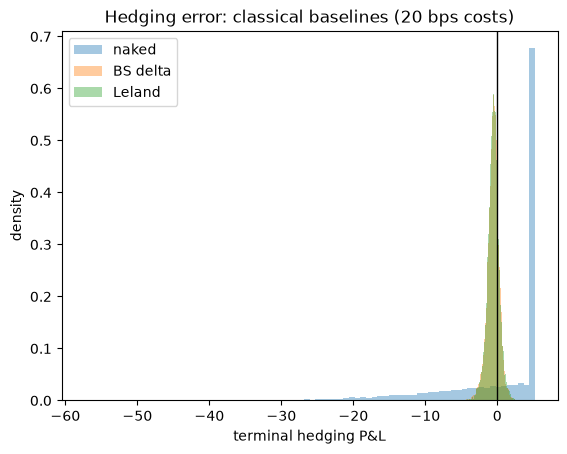

In [3]:
for name, e in [("naked", e_none), ("BS delta", e_bs), ("Leland", e_leland)]:
    plt.hist(-e, bins=80, alpha=0.4, label=name, density=True)
plt.axvline(0, color="k", lw=1)
plt.xlabel("terminal hedging P&L"); plt.ylabel("density"); plt.legend()
plt.title("Hedging error: classical baselines (20 bps costs)");

**What I took from this:** delta hedging already kills most of the variance, and Leland's tweak is free tail-risk reduction. The bar is higher than it looks. Notebook 02 is where the net has to earn its keep.